# AGD-Sentinel V2 — Modelo jerárquico final
**Modelo jerárquico de deterioro geotécnico acumulado (taludes coluviales de Toledo, Norte de Santander)**

Juan José Rangel (2243554) · Santiago Sepúlveda (2243557) · Jerónimo Andrés Mateo Bazán (2243590)
— Prof. David Romo Bucheli, PhD

Este cuaderno hace, en orden:
1. Carga los datos (48 ensayos de entrenamiento en 27 taludes + 2 de validación en Cortinas).
2. Ajusta el modelo jerárquico de 3 pisos con PyMC (NUTS).
3. Revisa convergencia, contracción (*pooling* parcial) y comprobación predictiva posterior.
4. Proyecta la cohesión y el factor de seguridad (FoS) de Cortinas en dos escenarios de fricción.
5. Repite el ajuste con dos priors alternativos para la tasa de deterioro (sensibilidad).
6. Compara el modelo con métodos ingenuos en los mismos casos y con la misma métrica (kPa).

Todo lo que se reporta en el informe queda guardado en la carpeta `resultados/`.
Las figuras se dibujan después con `generar_figuras_final.py` (no hace falta volver a muestrear).

In [1]:
import json
from pathlib import Path

import arviz as az
import numpy as np
import pandas as pd
import pymc as pm
import pytensor
from scipy.stats import truncnorm

# En nuestros equipos con Windows no hay compilador de C y PyTensor corre muy lento sin él.
# En ese caso usamos el backend Numba, que hace los mismos cálculos mucho más rápido.
if not pytensor.config.cxx:
    pytensor.config.mode = "NUMBA"

## 1. Configuración
Semilla fija, configuración del muestreador y constantes físicas del talud infinito.
La fricción **no** se estima: se evalúa en dos escenarios fijos tomados de Cortinas
(pico antes de la falla = 30.8°, residual después de la falla = 21.3°).

In [2]:
SEMILLA = 42
CADENAS, TUNE, DRAWS, TARGET_ACCEPT = 4, 2000, 3000, 0.95
NUCLEOS = 1          # 1 núcleo = funciona igual en Windows, Jupyter y Colab (las cadenas corren en serie)
PROB = 0.94          # nivel de todos los intervalos (HDI) del proyecto

# Talud infinito seco: FoS = c / (gamma z sin(beta) cos(beta)) + tan(phi) / tan(beta)
GAMMA, Z, BETA = 19.01, 13.0, np.radians(30.0)       # kN/m3, m, rad
PHI_PICO, PHI_RESIDUAL = 30.8, 21.3                   # grados (escenarios fijos)

# Prior de la tasa regional de deterioro, en la forma (mu, sigma) de una LogNormal
PRIOR_DELTA_BASE = (np.log(1.0), 0.75)                # mediana 1 kPa/año
PRIORS_DELTA = {
    "Base LogN(ln 1, 0.75)": PRIOR_DELTA_BASE,
    "Concentrado LogN(ln 1, 0.35)": (np.log(1.0), 0.35),
    "Difuso LogN(ln 1, 1.50)": (np.log(1.0), 1.50),
}

# Carpeta de trabajo: la del script o, dentro de Jupyter/Colab, la carpeta actual
try:
    CARPETA = Path(__file__).resolve().parent
except NameError:
    CARPETA = Path.cwd()
RESULTADOS = CARPETA / "resultados"
RESULTADOS.mkdir(exist_ok=True)


def buscar_csv(nombre):
    """Busca el CSV en la carpeta raíz, en datos/finales/ o en datosfinales/ (también en /content de Colab)."""
    for carpeta in [CARPETA, CARPETA / "datos" / "finales", CARPETA / "datosfinales",
                    Path("/content"), Path("/content/datosfinales")]:
        if (carpeta / nombre).exists():
            return carpeta / nombre
    raise FileNotFoundError(f"No se encontró {nombre}: póngalo junto al cuaderno o en datos/finales/")

## 2. Datos
Cada fila es un ensayo (corte directo o correlación SPT). `Sitio_idx` (0 a 26) dice a qué talud
pertenece la fila; con ese número el modelo le asigna a cada ensayo la cohesión inicial de su talud.
`t` son años desde el 1 de marzo de 2017.

In [3]:
train = pd.read_csv(buscar_csv("Dataset_Jerarquico_Maestro_Final.csv"))
valid = pd.read_csv(buscar_csv("Dataset_Validacion_Cortinas.csv"))

N_SITIOS = train["Sitio_idx"].nunique()
assert len(train) == 48 and N_SITIOS == 27, "Entrenamiento: 48 ensayos en 27 taludes"
assert train["Sitio_idx"].max() == N_SITIOS - 1, "Sitio_idx debe ir de 0 a 26 sin huecos"
assert len(valid) == 2 and (valid["Sitio_idx"] == 0).all(), "Validación: 2 ensayos de Cortinas"

c_obs = train["Cohesion"].to_numpy()
t_obs = train["t"].to_numpy()
sitio = train["Sitio_idx"].to_numpy()

# Cuántos ensayos tiene cada talud (17 de 27 tienen uno solo)
n_por_sitio = train.groupby("Sitio_idx").size()
nombres = train.groupby("Sitio_idx")["Sitio"].first()
print(f"Ensayos: {len(train)} | Taludes: {N_SITIOS} | Taludes con 1 solo ensayo: {(n_por_sitio == 1).sum()}")
print(f"Cohesión: media {c_obs.mean():.1f} kPa, mediana {np.median(c_obs):.1f} kPa, DE {c_obs.std(ddof=1):.1f} kPa")

Ensayos: 48 | Taludes: 27 | Taludes con 1 solo ensayo: 17
Cohesión: media 14.6 kPa, mediana 13.3 kPa, DE 7.8 kPa


## 3. Modelo jerárquico de 3 pisos
- **Piso 1 (región):** cohesión inicial media `mu_alpha`, variación entre taludes `sigma_alpha`
  y la tasa de pérdida compartida `delta_region` (> 0, por eso LogNormal).
- **Piso 2 (talud):** cohesión inicial de cada talud `alpha_sitio = mu_alpha + sigma_alpha * z`.
  Escribirla así (parametrización no centrada) es solo un truco numérico para que el muestreador
  no se atasque cuando casi todos los taludes tienen uno o dos ensayos.
- **Piso 3 (ensayo):** recta de deterioro `alpha_sitio - delta_region * t` y ruido de ensayo
  `sigma_obs`, con una Normal **truncada en cero** (una cohesión negativa no existe).

In [4]:
def construir_modelo(c, t, idx, prior_delta=PRIOR_DELTA_BASE):
    with pm.Model(coords={"sitio": np.arange(N_SITIOS)}) as modelo:
        # Piso 1: región
        mu_alpha = pm.Normal("mu_alpha", mu=15.0, sigma=10.0)
        sigma_alpha = pm.HalfNormal("sigma_alpha", sigma=5.0)
        delta_region = pm.LogNormal("delta_region", mu=prior_delta[0], sigma=prior_delta[1])
        # Piso 2: talud (no centrada)
        z_sitio = pm.Normal("z_sitio", mu=0.0, sigma=1.0, dims="sitio")
        alpha_sitio = pm.Deterministic("alpha_sitio", mu_alpha + sigma_alpha * z_sitio, dims="sitio")
        # Piso 3: ensayo
        sigma_obs = pm.HalfNormal("sigma_obs", sigma=5.0)
        mu_c = alpha_sitio[idx] - delta_region * t
        pm.TruncatedNormal("c_obs", mu=mu_c, sigma=sigma_obs, lower=0.0, observed=c)
    return modelo


def muestrear(modelo, target_accept=TARGET_ACCEPT):
    with modelo:
        return pm.sample(draws=DRAWS, tune=TUNE, chains=CADENAS, cores=NUCLEOS,
                         target_accept=target_accept, random_seed=SEMILLA, progressbar=False)


def diagnostico(idata):
    """R-hat máximo, ESS mínimo y número de divergencias de un ajuste."""
    s = az.summary(idata, var_names=["mu_alpha", "sigma_alpha", "delta_region", "sigma_obs", "z_sitio"])
    return {"rhat_max": float(s["r_hat"].max()), "ess_bulk_min": float(s["ess_bulk"].min()),
            "ess_tail_min": float(s["ess_tail"].min()),
            "divergencias": int(idata.sample_stats["diverging"].sum())}


def hdi(muestras, prob=PROB):
    """HDI de un vector de muestras -> (inferior, superior)."""
    return tuple(float(v) for v in az.hdi(np.asarray(muestras), hdi_prob=prob))


def fos(c, phi_grados):
    """Factor de seguridad de talud infinito seco."""
    return c / (GAMMA * Z * np.sin(BETA) * np.cos(BETA)) + np.tan(np.radians(phi_grados)) / np.tan(BETA)


def phi_critico(c):
    """Fricción (grados) con la que el talud llega justo a FoS = 1, dada la cohesión c."""
    return np.degrees(np.arctan(np.tan(BETA) * (1 - c / (GAMMA * Z * np.sin(BETA) * np.cos(BETA)))))


def cohesion_nueva(mu, sigma, rng):
    """Simula un ensayo futuro: Normal truncada en 0 alrededor de la recta (incluye el ruido)."""
    return truncnorm.rvs(-mu / sigma, np.inf, loc=mu, scale=sigma, random_state=rng)


def extraer(idata):
    """Muestras posteriores apiladas (4 cadenas x 3000 = 12 000 por parámetro)."""
    p = idata.posterior.stack(m=("chain", "draw"))
    return {"alpha": p["alpha_sitio"].values.T, "delta": p["delta_region"].values,
            "sigma": p["sigma_obs"].values, "mu_alpha": p["mu_alpha"].values,
            "sigma_alpha": p["sigma_alpha"].values}

## 4. Ajuste del modelo base
Las 48 cohesiones de entrenamiento entran a la verosimilitud. NUTS: 4 cadenas,
2000 iteraciones de calentamiento y 3000 muestras por cadena, `target_accept = 0.95`, semilla 42.
También tomamos muestras del prior para medir cuánto aprendió el modelo de los datos.

In [5]:
modelo_base = construir_modelo(c_obs, t_obs, sitio)
idata = muestrear(modelo_base)
with modelo_base:
    idata.extend(pm.sample_prior_predictive(12000, random_seed=SEMILLA))
    idata.extend(pm.sample_posterior_predictive(idata, random_seed=SEMILLA, progressbar=False))
post = extraer(idata)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [mu_alpha, sigma_alpha, delta_region, z_sitio, sigma_obs]


Sampling 4 chains for 2_000 tune and 3_000 draw iterations (8_000 + 12_000 draws total) took 12 seconds.


Sampling: [c_obs, delta_region, mu_alpha, sigma_alpha, sigma_obs, z_sitio]


Sampling: [c_obs]


## 5. Diagnósticos de convergencia y contracción
**Convergencia:** las 4 cadenas deben coincidir (R-hat ≤ 1.01), tener suficientes muestras
independientes (ESS > 2000) y no presentar divergencias.

In [6]:
diag = diagnostico(idata)
print(f"R-hat máximo   : {diag['rhat_max']:.3f}  (meta <= 1.01)")
print(f"ESS bulk mínimo: {diag['ess_bulk_min']:.0f}  (meta > 2000)")
print(f"ESS tail mínimo: {diag['ess_tail_min']:.0f}")
print(f"Divergencias   : {diag['divergencias']}  (meta = 0)")
assert diag["rhat_max"] <= 1.01 and diag["ess_bulk_min"] > 2000 and diag["divergencias"] == 0

resumen = az.summary(idata, var_names=["mu_alpha", "sigma_alpha", "delta_region", "sigma_obs", "alpha_sitio"],
                     hdi_prob=PROB)
resumen.round(3).to_csv(RESULTADOS / "resumen_posterior.csv")
resumen.loc[["mu_alpha", "sigma_alpha", "delta_region", "sigma_obs"]].round(2)

R-hat máximo   : 1.000  (meta <= 1.01)
ESS bulk mínimo: 2882  (meta > 2000)
ESS tail mínimo: 3941
Divergencias   : 0  (meta = 0)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_alpha,16.12,1.87,12.63,19.69,0.03,0.02,3724.0,4731.0,1.0
sigma_alpha,7.32,1.52,4.52,10.20,0.03,0.02,2882.0,3941.0,1.0
delta_region,1.37,0.57,0.36,2.40,0.01,0.00,5281.0,5696.0,1.0
sigma_obs,4.68,0.88,3.22,6.32,0.02,0.02,3033.0,4406.0,1.0


**Contracción (cuánto se encogió la incertidumbre):** `1 - varianza posterior / varianza prior`.
Un valor cercano a 1 dice que los datos dominaron; cercano a 0, que manda el prior.

In [7]:
prior = idata.prior.stack(m=("chain", "draw"))


def contraccion(nombre, i=None):
    a = prior[nombre].values if i is None else prior[nombre].values[i]
    b = idata.posterior.stack(m=("chain", "draw"))[nombre].values
    b = b if i is None else b[i]
    return 1 - b.var() / a.var()


tabla_contraccion = pd.DataFrame({
    "parametro": ["mu_alpha", "sigma_alpha", "delta_region", "sigma_obs"],
    "sd_prior": [prior[v].values.std() for v in ["mu_alpha", "sigma_alpha", "delta_region", "sigma_obs"]],
    "sd_posterior": [idata.posterior[v].values.std() for v in ["mu_alpha", "sigma_alpha", "delta_region", "sigma_obs"]],
    "contraccion": [contraccion(v) for v in ["mu_alpha", "sigma_alpha", "delta_region", "sigma_obs"]],
})
tabla_contraccion.round(3).to_csv(RESULTADOS / "contraccion.csv", index=False)
tabla_contraccion.round(2)

,parametro,sd_prior,sd_posterior,contraccion
0,mu_alpha,10.10,1.87,0.97
1,sigma_alpha,2.99,1.52,0.74
2,delta_region,1.17,0.57,0.77
3,sigma_obs,2.98,0.88,0.91


**Pooling parcial en los 27 taludes.** Para cada talud comparamos:
- *Solo con sus datos* (sin pooling): la cohesión inicial que diría el talud por sí solo,
  `promedio(c + delta * t)`. Con un único ensayo esto equivale a creerle ciegamente a ese ensayo.
- *Modelo jerárquico*: la media posterior de `alpha_sitio`.

El **factor de jalón** mide qué fracción del camino hacia la media regional recorrió cada talud.
La teoría dice que debe ser `(sigma_obs²/n) / (sigma_obs²/n + sigma_alpha²)`: grande si el talud
tiene pocos ensayos (n = 1) y pequeño si tiene muchos.

In [8]:
delta_media = post["delta"].mean()
mu_alpha_media = post["mu_alpha"].mean()
s2_obs, s2_alpha = (post["sigma"] ** 2).mean(), (post["sigma_alpha"] ** 2).mean()

filas = []
for i in range(N_SITIOS):
    d = train[train["Sitio_idx"] == i]
    solo_datos = float((d["Cohesion"] + delta_media * d["t"]).mean())
    jerarquico = float(post["alpha"][:, i].mean())
    lo, hi = hdi(post["alpha"][:, i])
    n = len(d)
    filas.append({"Sitio_idx": i, "Sitio": nombres[i], "n": n, "t": float(d["t"].iloc[0]),
                  "solo_sus_datos": solo_datos, "alpha_media": jerarquico, "alpha_hdi_inf": lo,
                  "alpha_hdi_sup": hi, "alpha_sd": float(post["alpha"][:, i].std()),
                  "jalon_observado": (solo_datos - jerarquico) / (solo_datos - mu_alpha_media),
                  "jalon_teorico": (s2_obs / n) / (s2_obs / n + s2_alpha)})
pooling = pd.DataFrame(filas)
pooling.round(3).to_csv(RESULTADOS / "pooling_sitios.csv", index=False)

# Taludes con un único ensayo: ¿cuánto los jaló el modelo hacia la región?
uno = pooling[pooling["n"] == 1]
# El jalón observado es inestable cuando el dato cae casi encima de la media regional; usamos la mediana
print(f"Taludes con n = 1: {len(uno)}")
print(f"  Jalón hacia la media regional: mediana observada {uno['jalon_observado'].median():.2f}, "
      f"teórico {uno['jalon_teorico'].iloc[0]:.2f}")
print(f"  Distancia a la media regional: sin pooling {np.abs(uno['solo_sus_datos'] - mu_alpha_media).mean():.1f} kPa"
      f" -> jerárquico {np.abs(uno['alpha_media'] - mu_alpha_media).mean():.1f} kPa")

# Sobreajuste: una recta propia por talud con 1 ensayo tiene 2 incógnitas y 1 dato (error 0 = sobreajuste).
mu_c_post = post["alpha"][:, sitio] - post["delta"][:, None] * t_obs
residuo_uno = np.abs(c_obs - mu_c_post.mean(0))[np.isin(sitio, uno["Sitio_idx"])]
print(f"  Error de ajuste dentro de muestra en esos 17 ensayos: {residuo_uno.mean():.1f} kPa "
      f"(una regresión propia daría 0 kPa: memoriza el dato)")
pooling.loc[:, ["Sitio", "n", "solo_sus_datos", "alpha_media", "alpha_sd", "jalon_teorico"]].round(2)

Taludes con n = 1: 17
  Jalón hacia la media regional: mediana observada 0.30, teórico 0.29
  Distancia a la media regional: sin pooling 6.7 kPa -> jerárquico 4.8 kPa
  Error de ajuste dentro de muestra en esos 17 ensayos: 1.9 kPa (una regresión propia daría 0 kPa: memoriza el dato)


,Sitio,n,solo_sus_datos,alpha_media,alpha_sd,jalon_teorico
0,Cortinas,2,17.93,17.49,3.22,0.17
1,PR-25-20-39,1,15.00,14.38,5.07,0.29
2,PR-21-01-38,11,21.40,21.09,2.95,0.04
3,AVR- FASE II Tramo 15,1,17.00,16.71,3.92,0.29
4,AVR- FASE II Tramo 1,1,12.00,13.13,3.98,0.29
5,AVR- FASE II Tramo 5,1,20.00,18.82,3.94,0.29
6,AVR- FASE II Tramo 6,1,19.00,18.05,4.01,0.29
7,AVR- FASE II Tramo 37,1,7.00,9.34,4.39,0.29
8,AVR- FASE II Tramo 42,1,12.00,13.06,4.07,0.29
9,AVR- FASE II Tramo 65,1,9.00,10.87,4.19,0.29


## 6. Comprobación predictiva posterior (PPC)
Simulamos 12 000 bases de datos "falsas" de 48 ensayos con los parámetros posteriores y
comprobamos si la base real se parece a ellas en: dispersión, mínimo (piso en cero),
fracción de cohesiones casi nulas (< 1 kPa), máximo y la caída de Cortinas entre 2017 y 2021.
El valor *p* bayesiano es la fracción de réplicas con un estadístico mayor o igual al observado;
valores entre 0.05 y 0.95 indican que el modelo reproduce ese rasgo.

In [9]:
c_rep = idata.posterior_predictive["c_obs"].stack(m=("chain", "draw")).values.T   # (12000, 48)

estadisticos = {
    "Media (kPa)": lambda x: x.mean(axis=-1),
    "Desviación estándar (kPa)": lambda x: x.std(axis=-1, ddof=1),
    "Mínimo (kPa)": lambda x: x.min(axis=-1),
    "Máximo (kPa)": lambda x: x.max(axis=-1),
    "Fracción < 1 kPa": lambda x: (x < 1).mean(axis=-1),
    "Caída Cortinas 2017-2021 (kPa)": lambda x: x[..., 0] - x[..., 1],
}
filas = []
for nombre, f in estadisticos.items():
    obs, rep = float(f(c_obs)), f(c_rep)
    lo, hi = np.quantile(rep, [0.03, 0.97])
    filas.append({"estadistico": nombre, "observado": obs, "replica_media": float(rep.mean()),
                  "replica_q03": float(lo), "replica_q97": float(hi), "p_bayes": float((rep >= obs).mean())})
ppc = pd.DataFrame(filas)
ppc.round(3).to_csv(RESULTADOS / "ppc.csv", index=False)

# ¿Qué pasaría sin la truncación? Misma recta y mismo ruido, pero Normal sin piso en cero
rng = np.random.default_rng(SEMILLA)
c_rep_sin_truncar = rng.normal(mu_c_post, post["sigma"][:, None])
frac_neg_sin_truncar = float((c_rep_sin_truncar < 0).mean())
print(f"Réplicas con c < 0 -> modelo truncado: {(c_rep < 0).mean():.3%} | Normal sin truncar: {frac_neg_sin_truncar:.2%}")
ppc.round(2)

Réplicas con c < 0 -> modelo truncado: 0.000% | Normal sin truncar: 6.50%


,estadistico,observado,replica_media,replica_q03,replica_q97,p_bayes
0,Media (kPa),14.55,14.54,12.81,16.30,0.48
1,Desviación estándar (kPa),7.79,7.72,6.36,9.20,0.45
2,Mínimo (kPa),0.10,0.75,0.02,2.65,0.87
3,Máximo (kPa),34.00,33.56,26.97,42.06,0.42
4,Fracción < 1 kPa,0.08,0.03,0.00,0.08,0.03
5,Caída Cortinas 2017-2021 (kPa),6.40,5.09,-7.84,18.09,0.42


## 7. Proyección de Cortinas (talud 0) y factor de seguridad
- **Banda de credibilidad** (para la recta media): incertidumbre de `alpha_0` y `delta_region`.
- **Banda predictiva** (para un ensayo nuevo): además suma el ruido de un ensayo (`sigma_obs`).
- **FoS** en los dos escenarios fijos de fricción y la fricción crítica que llevaría a FoS = 1.

In [10]:
a0, d, s = post["alpha"][:, 0], post["delta"], post["sigma"]
t_grid = np.round(np.linspace(0, 8, 161), 3)
recta = a0[:, None] - d[:, None] * t_grid                       # (12000, 161)
c_media = np.maximum(recta, 0.0)                                 # la cohesión no baja de 0
c_pred = cohesion_nueva(recta, s[:, None], rng)                  # ensayo futuro con ruido

grid = {"t": t_grid, "c_media": c_media.mean(0), "c_mediana_pred": np.median(c_pred, 0)}
grid["c_cred_inf"], grid["c_cred_sup"] = np.array([hdi(c_media[:, j]) for j in range(len(t_grid))]).T
grid["c_pred_inf"], grid["c_pred_sup"] = np.array([hdi(c_pred[:, j]) for j in range(len(t_grid))]).T
for nombre, phi in [("pico", PHI_PICO), ("residual", PHI_RESIDUAL)]:
    f = fos(c_media, phi)
    grid[f"fos_{nombre}"] = f.mean(0)
    grid[f"fos_{nombre}_inf"], grid[f"fos_{nombre}_sup"] = np.array([hdi(f[:, j]) for j in range(len(t_grid))]).T
proyeccion = pd.DataFrame(grid)
proyeccion.round(4).to_csv(RESULTADOS / "cortinas_proyeccion.csv", index=False)

# Puntos clave: inicio, falla, y las dos fechas de validación
filas = []
for t_k in [0.0, train.loc[1, "t"], *valid["t"]]:
    rec = a0 - d * t_k
    ck = np.maximum(rec, 0)
    fila = {"t": t_k, "c_media": ck.mean(), "c_inf": hdi(ck)[0], "c_sup": hdi(ck)[1],
            "phi_critico": phi_critico(ck).mean(), "phi_crit_inf": hdi(phi_critico(ck))[0],
            "phi_crit_sup": hdi(phi_critico(ck))[1]}
    for nombre, phi in [("pico", PHI_PICO), ("residual", PHI_RESIDUAL)]:
        fk = fos(ck, phi)
        fila |= {f"fos_{nombre}": fk.mean(), f"fos_{nombre}_inf": hdi(fk)[0], f"fos_{nombre}_sup": hdi(fk)[1],
                 f"p_falla_{nombre}": (fk <= 1).mean()}
    filas.append(fila)
puntos_clave = pd.DataFrame(filas)
puntos_clave.round(3).to_csv(RESULTADOS / "cortinas_puntos_clave.csv", index=False)
puntos_clave.round(3)

,t,c_media,c_inf,c_sup,phi_critico,phi_crit_inf,phi_crit_sup,fos_pico,fos_pico_inf,fos_pico_sup,p_falla_pico,fos_residual,fos_residual_inf,fos_residual_sup,p_falla_residual
0,0.000,17.490,11.135,23.299,25.775,24.306,27.351,1.196,1.137,1.250,0.0,0.839,0.779,0.893,1.0
1,3.838,12.228,5.785,18.301,27.078,25.612,28.676,1.147,1.087,1.204,0.0,0.790,0.729,0.846,1.0
2,5.837,9.504,2.012,16.612,27.740,26.002,29.534,1.121,1.051,1.188,0.0,0.764,0.694,0.831,1.0
3,7.838,6.939,0.000,13.706,28.355,26.721,30.000,1.097,1.033,1.161,0.0,0.740,0.675,0.803,1.0


## 8. Sensibilidad al prior de la tasa regional
Casi toda la información sobre `delta_region` viene de una sola caída (Cortinas, 18.5 → 12.1 kPa).
Reajustamos el modelo con un prior más concentrado y otro más difuso, con la misma mediana (1 kPa/año),
y comparamos la tasa, la cohesión y el FoS proyectados para 2025 (t = 7.84 años).

In [11]:
T_2025 = float(valid["t"].iloc[1])
ajustes = {"Base LogN(ln 1, 0.75)": idata}
for nombre, prior_d in PRIORS_DELTA.items():
    if nombre not in ajustes:
        ajustes[nombre] = muestrear(construir_modelo(c_obs, t_obs, sitio, prior_d))

filas, deltas = [], {}
for nombre, idata_k in ajustes.items():
    p = extraer(idata_k)
    mu_d, sd_d = PRIORS_DELTA[nombre]
    ck = np.maximum(p["alpha"][:, 0] - p["delta"] * T_2025, 0)
    fp, fr = fos(ck, PHI_PICO), fos(ck, PHI_RESIDUAL)
    deltas[nombre] = p["delta"]
    filas.append({"prior": nombre,
                  "prior_q03": float(np.exp(mu_d - 1.881 * sd_d)), "prior_q97": float(np.exp(mu_d + 1.881 * sd_d)),
                  "delta_media": p["delta"].mean(), "delta_inf": hdi(p["delta"])[0], "delta_sup": hdi(p["delta"])[1],
                  "c_2025_media": ck.mean(), "c_2025_inf": hdi(ck)[0], "c_2025_sup": hdi(ck)[1],
                  "fos_pico_2025": fp.mean(), "fos_residual_2025": fr.mean(),
                  "p_falla_pico_2025": (fp <= 1).mean(), "p_falla_residual_2025": (fr <= 1).mean(),
                  **diagnostico(idata_k)})
sensibilidad = pd.DataFrame(filas)
sensibilidad.round(3).to_csv(RESULTADOS / "sensibilidad_priors.csv", index=False)
np.savez(RESULTADOS / "delta_por_prior.npz", **{f"d{i}": v for i, v in enumerate(deltas.values())})
sensibilidad.iloc[:, :12].round(2)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [mu_alpha, sigma_alpha, delta_region, z_sitio, sigma_obs]


Sampling 4 chains for 2_000 tune and 3_000 draw iterations (8_000 + 12_000 draws total) took 11 seconds.


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [mu_alpha, sigma_alpha, delta_region, z_sitio, sigma_obs]


Sampling 4 chains for 2_000 tune and 3_000 draw iterations (8_000 + 12_000 draws total) took 14 seconds.


,prior,prior_q03,prior_q97,delta_media,delta_inf,delta_sup,c_2025_media,c_2025_inf,c_2025_sup,fos_pico_2025,fos_residual_2025,p_falla_pico_2025
0,"Base LogN(ln 1, 0.75)",0.24,4.10,1.37,0.36,2.40,6.94,0.0,13.71,1.10,0.74,0.0
1,"Concentrado LogN(ln 1, 0.35)",0.52,1.93,1.20,0.56,1.88,7.81,0.0,13.35,1.11,0.75,0.0
2,"Difuso LogN(ln 1, 1.50)",0.06,16.80,1.39,0.17,2.59,6.93,0.0,14.28,1.10,0.74,0.0


## 9. Evaluación frente a métodos ingenuos
### 9a. Pronóstico hacia adelante en Cortinas (t = 5.84 y 7.84 años, después de la falla)
Información disponible al predecir: solo los ensayos hasta 2021. Mismos 2 casos y misma métrica
(error absoluto medio, MAE, en kPa) para todos:
- **Modelo bayesiano**: mediana de la predictiva de un ensayo nuevo + intervalo predictivo del 94 %.
- **Persistencia**: la cohesión se queda en el último valor medido (12.1 kPa).
- **Mediana de entrenamiento**: 13.3 kPa, con el intervalo empírico 3 %–97 % de los 48 ensayos.
- **Secante de 2 puntos**: la recta que pasa por 18.5 kPa (2017) y 12.1 kPa (2021), sin incertidumbre.

In [12]:
t_val, c_val = valid["t"].to_numpy(), valid["Cohesion"].to_numpy()
c_val_pred = cohesion_nueva(a0[:, None] - d[:, None] * t_val, s[:, None], rng)     # (12000, 2)
ultimo = float(train.loc[1, "Cohesion"])
mediana_train = float(np.median(c_obs))
emp_inf, emp_sup = np.quantile(c_obs, [0.03, 0.97])
pendiente_secante = (train.loc[0, "Cohesion"] - train.loc[1, "Cohesion"]) / train.loc[1, "t"]

metodos = {
    "Modelo bayesiano jerárquico": (np.median(c_val_pred, 0),
                                    np.array([hdi(c_val_pred[:, j]) for j in range(2)])),
    "Persistencia (último valor 12.1 kPa)": (np.full(2, ultimo), None),
    "Mediana de entrenamiento (13.3 kPa)": (np.full(2, mediana_train), np.tile([emp_inf, emp_sup], (2, 1))),
    "Secante de 2 puntos (Avance 1)": (train.loc[0, "Cohesion"] - pendiente_secante * t_val, None),
}


def evaluar(nombre, punto, intervalo, real):
    fila = {"metodo": nombre, "MAE_kPa": float(np.abs(punto - real).mean()), "n_casos": len(real)}
    if intervalo is not None:
        dentro = (real >= intervalo[:, 0]) & (real <= intervalo[:, 1])
        fila |= {"cobertura": f"{dentro.sum()} de {len(real)}", "amplitud_media_kPa": float((intervalo[:, 1] - intervalo[:, 0]).mean())}
    else:
        fila |= {"cobertura": "sin intervalo", "amplitud_media_kPa": np.nan}
    return fila


ingenuo_long = pd.DataFrame([evaluar(k, *v, c_val) for k, v in metodos.items()])
detalle_long = pd.DataFrame({"t": t_val, "c_real": c_val,
                             **{k: v[0] for k, v in metodos.items()},
                             "bayes_inf": metodos["Modelo bayesiano jerárquico"][1][:, 0],
                             "bayes_sup": metodos["Modelo bayesiano jerárquico"][1][:, 1],
                             "P(c_pred < c_real)": (c_val_pred < c_val).mean(0)})
ingenuo_long.round(2).to_csv(RESULTADOS / "ingenuo_cortinas.csv", index=False)
detalle_long.round(3).to_csv(RESULTADOS / "ingenuo_cortinas_detalle.csv", index=False)
print(f"La secante cruza c = 0 en t = {train.loc[0, 'Cohesion'] / pendiente_secante:.1f} años; "
      f"a t = 15 predice {train.loc[0, 'Cohesion'] - pendiente_secante * 15:.1f} kPa (imposible).")
ingenuo_long.round(2)

La secante cruza c = 0 en t = 11.1 años; a t = 15 predice -6.5 kPa (imposible).


,metodo,MAE_kPa,n_casos,cobertura,amplitud_media_kPa
0,Modelo bayesiano jerárquico,8.10,2,1 de 2,17.96
1,Persistencia (último valor 12.1 kPa),4.65,2,sin intervalo,NaN
2,Mediana de entrenamiento (13.3 kPa),3.48,2,2 de 2,30.08
3,Secante de 2 puntos (Avance 1),9.65,2,sin intervalo,NaN


### 9b. Predicción entre taludes (validación cruzada de 2 particiones)
Pregunta: ¿predice mejor el modelo jerárquico un ensayo nuevo en un talud ya conocido?
Usamos los 9 taludes (sin Cortinas) que tienen 2 o más ensayos: 29 ensayos. En cada talud
los ensayos se reparten alternadamente en dos grupos; se ajusta el modelo sin un grupo y se
predice ese grupo (cada talud conserva al menos un ensayo en el entrenamiento). Así los 29
ensayos se predicen una vez cada uno, sin haberlos visto. Métodos, en los mismos 29 casos:
- **Modelo bayesiano jerárquico** (mediana predictiva + intervalo predictivo del 94 %).
- **Mediana global de entrenamiento** (ingenuo, sin jerarquía) + intervalo empírico 3 %–97 %.
- **Promedio del propio talud** (sin pooling: cada talud por su cuenta).

In [13]:
multi = [i for i in range(1, N_SITIOS) if n_por_sitio[i] >= 2]
train["grupo_cv"] = -1
for i in multi:
    filas_i = train.index[train["Sitio_idx"] == i]
    train.loc[filas_i, "grupo_cv"] = np.arange(len(filas_i)) % 2

predicciones = []
for k in [0, 1]:
    prueba = train["grupo_cv"] == k
    tr = train[~prueba]
    # Con menos datos por talud el muestreador necesita pasos más cortos: target_accept = 0.99
    idata_k = muestrear(construir_modelo(tr["Cohesion"].to_numpy(), tr["t"].to_numpy(), tr["Sitio_idx"].to_numpy()),
                        target_accept=0.99)
    p = extraer(idata_k)
    print(f"Partición {k}: {diagnostico(idata_k)}")
    med_k = float(tr["Cohesion"].median())
    lo_k, hi_k = np.quantile(tr["Cohesion"], [0.03, 0.97])
    for _, fila in train[prueba].iterrows():
        j = int(fila["Sitio_idx"])
        cp = cohesion_nueva(p["alpha"][:, j] - p["delta"] * fila["t"], p["sigma"], rng)
        b_inf, b_sup = hdi(cp)
        predicciones.append({"particion": k, "Sitio_idx": j, "Sitio": fila["Sitio"], "c_real": fila["Cohesion"],
                             "bayes": float(np.median(cp)), "bayes_inf": b_inf, "bayes_sup": b_sup,
                             "mediana_global": med_k, "global_inf": lo_k, "global_sup": hi_k,
                             "promedio_talud": float(tr.loc[tr["Sitio_idx"] == j, "Cohesion"].mean())})
cv = pd.DataFrame(predicciones)
cv.round(3).to_csv(RESULTADOS / "ingenuo_regional_detalle.csv", index=False)

real = cv["c_real"].to_numpy()
ingenuo_reg = pd.DataFrame([
    evaluar("Modelo bayesiano jerárquico", cv["bayes"].to_numpy(), cv[["bayes_inf", "bayes_sup"]].to_numpy(), real),
    evaluar("Mediana global (ingenuo)", cv["mediana_global"].to_numpy(), cv[["global_inf", "global_sup"]].to_numpy(), real),
    evaluar("Promedio del propio talud (sin pooling)", cv["promedio_talud"].to_numpy(), None, real),
])

ingenuo_reg.round(2).to_csv(RESULTADOS / "ingenuo_regional.csv", index=False)
ingenuo_reg.round(2)

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [mu_alpha, sigma_alpha, delta_region, z_sitio, sigma_obs]


Sampling 4 chains for 2_000 tune and 3_000 draw iterations (8_000 + 12_000 draws total) took 26 seconds.


Partición 0: {'rhat_max': 1.01, 'ess_bulk_min': 686.0, 'ess_tail_min': 2266.0, 'divergencias': 0}


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [mu_alpha, sigma_alpha, delta_region, z_sitio, sigma_obs]


Sampling 4 chains for 2_000 tune and 3_000 draw iterations (8_000 + 12_000 draws total) took 26 seconds.


Partición 1: {'rhat_max': 1.0, 'ess_bulk_min': 884.0, 'ess_tail_min': 805.0, 'divergencias': 0}


,metodo,MAE_kPa,n_casos,cobertura,amplitud_media_kPa
0,Modelo bayesiano jerárquico,4.66,29,26 de 29,20.31
1,Mediana global (ingenuo),5.78,29,26 de 29,29.04
2,Promedio del propio talud (sin pooling),4.47,29,sin intervalo,NaN


## 10. Resumen numérico de resultados
Guardamos las cifras clave en `resultados/resumen.json` y el ajuste completo en
`resultados/idata_base.nc` (lo usa `generar_figuras_final.py`).

In [14]:
def mh(x):
    """Media y HDI 94 % redondeados."""
    lo, hi = hdi(x)
    return {"media": round(float(np.mean(x)), 3), "hdi_inf": round(lo, 3), "hdi_sup": round(hi, 3)}


resumen_json = {
    "configuracion": {"semilla": SEMILLA, "cadenas": CADENAS, "tune": TUNE, "draws": DRAWS,
                      "target_accept": TARGET_ACCEPT, "pymc": pm.__version__, "arviz": az.__version__},
    "datos": {"n_train": len(train), "n_valid": len(valid), "n_sitios": N_SITIOS,
              "sitios_n1": int((n_por_sitio == 1).sum()), "mediana_train": mediana_train,
              "media_train": float(c_obs.mean()), "sd_train": float(c_obs.std(ddof=1)),
              "emp_q03": float(emp_inf), "emp_q97": float(emp_sup)},
    "diagnostico": diag,
    "parametros": {v: mh(post[k]) for v, k in [("mu_alpha", "mu_alpha"), ("sigma_alpha", "sigma_alpha"),
                                                ("delta_region", "delta"), ("sigma_obs", "sigma")]},
    "alpha_cortinas": mh(a0),
    "p_delta_mayor_1": float((d > 1).mean()),
    "pooling_n1": {"jalon_mediano": float(uno["jalon_observado"].median()),
                   "jalon_teorico": float(uno["jalon_teorico"].iloc[0]),
                   "dist_sin_pooling": float(np.abs(uno["solo_sus_datos"] - mu_alpha_media).mean()),
                   "dist_jerarquico": float(np.abs(uno["alpha_media"] - mu_alpha_media).mean()),
                   "error_in_sample": float(residuo_uno.mean()),
                   "sd_alpha_n1": float(uno["alpha_sd"].mean())},
    "ppc_frac_negativos_sin_truncar": frac_neg_sin_truncar,
    "prior_predictiva_c": {"mediana": float(np.median(idata.prior_predictive["c_obs"].values)),
                           "q03": float(np.quantile(idata.prior_predictive["c_obs"].values, 0.03)),
                           "q97": float(np.quantile(idata.prior_predictive["c_obs"].values, 0.97))},
    "secante_cruce_cero": float(train.loc[0, "Cohesion"] / pendiente_secante),
}
(RESULTADOS / "resumen.json").write_text(json.dumps(resumen_json, indent=2, ensure_ascii=False), encoding="utf-8")
idata.to_netcdf(RESULTADOS / "idata_base.nc")
print(json.dumps(resumen_json, indent=2, ensure_ascii=False))

{
  "configuracion": {
    "semilla": 42,
    "cadenas": 4,
    "tune": 2000,
    "draws": 3000,
    "target_accept": 0.95,
    "pymc": "5.28.5",
    "arviz": "0.23.4"
  },
  "datos": {
    "n_train": 48,
    "n_valid": 2,
    "n_sitios": 27,
    "sitios_n1": 17,
    "mediana_train": 13.265,
    "media_train": 14.554583333333333,
    "sd_train": 7.785226313914403,
    "emp_q03": 0.1,
    "emp_q97": 30.179999999999993
  },
  "diagnostico": {
    "rhat_max": 1.0,
    "ess_bulk_min": 2882.0,
    "ess_tail_min": 3941.0,
    "divergencias": 0
  },
  "parametros": {
    "mu_alpha": {
      "media": 16.118,
      "hdi_inf": 12.63,
      "hdi_sup": 19.693
    },
    "sigma_alpha": {
      "media": 7.317,
      "hdi_inf": 4.521,
      "hdi_sup": 10.195
    },
    "delta_region": {
      "media": 1.371,
      "hdi_inf": 0.357,
      "hdi_sup": 2.397
    },
    "sigma_obs": {
      "media": 4.679,
      "hdi_inf": 3.223,
      "hdi_sup": 6.318
    }
  },
  "alpha_cortinas": {
    "media": 17.49,


## 11. Figuras
Se dibujan con `generar_figuras_final.py` a partir de `resultados/` y quedan en `figuras/` (PNG y PDF).

Generando figuras en figuras/ ...


  figuras/fig1_datos.png


  figuras/fig2_pooling_parcial.png


  figuras/fig3_ppc.png


  figuras/fig7_cortinas_pronostico.png


  figuras/fig8_fos_escenarios.png
  figuras/fig4_sensibilidad_prior.png


  figuras/fig5_comparacion_ingenuo.png


  figuras/fig6_predicho_vs_observado.png


  figuras/anexo_trazas.png
Listo.


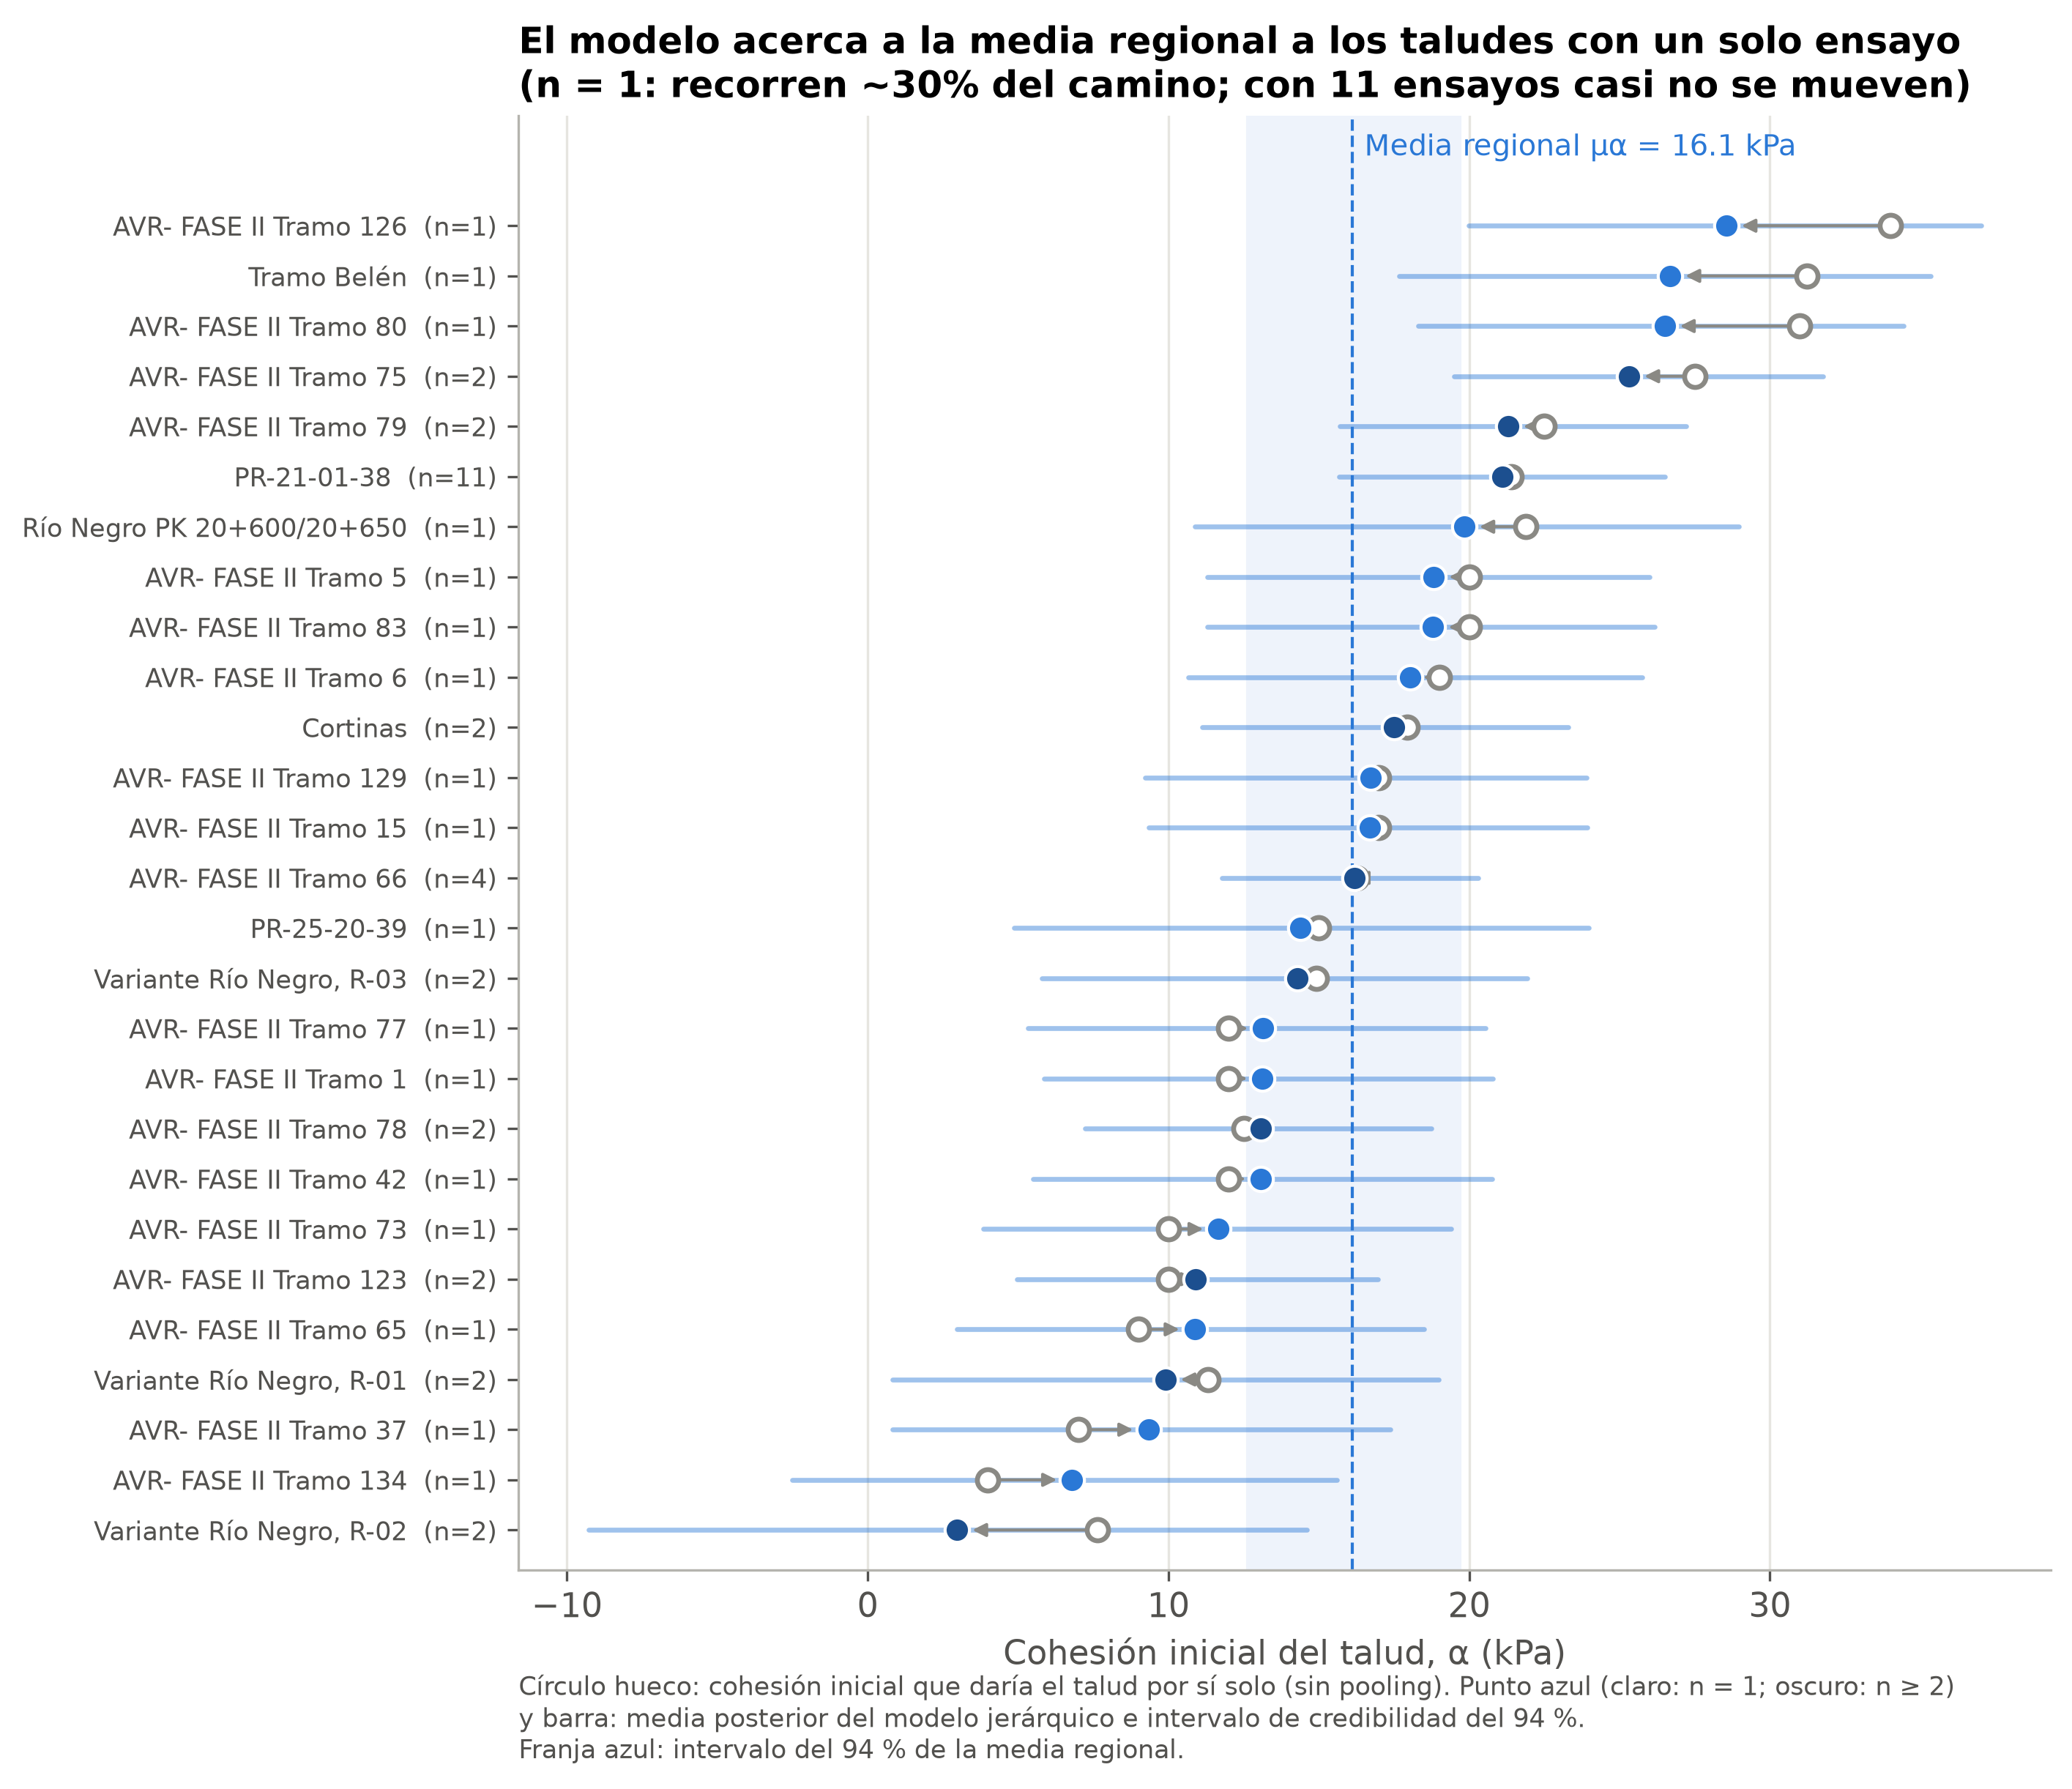

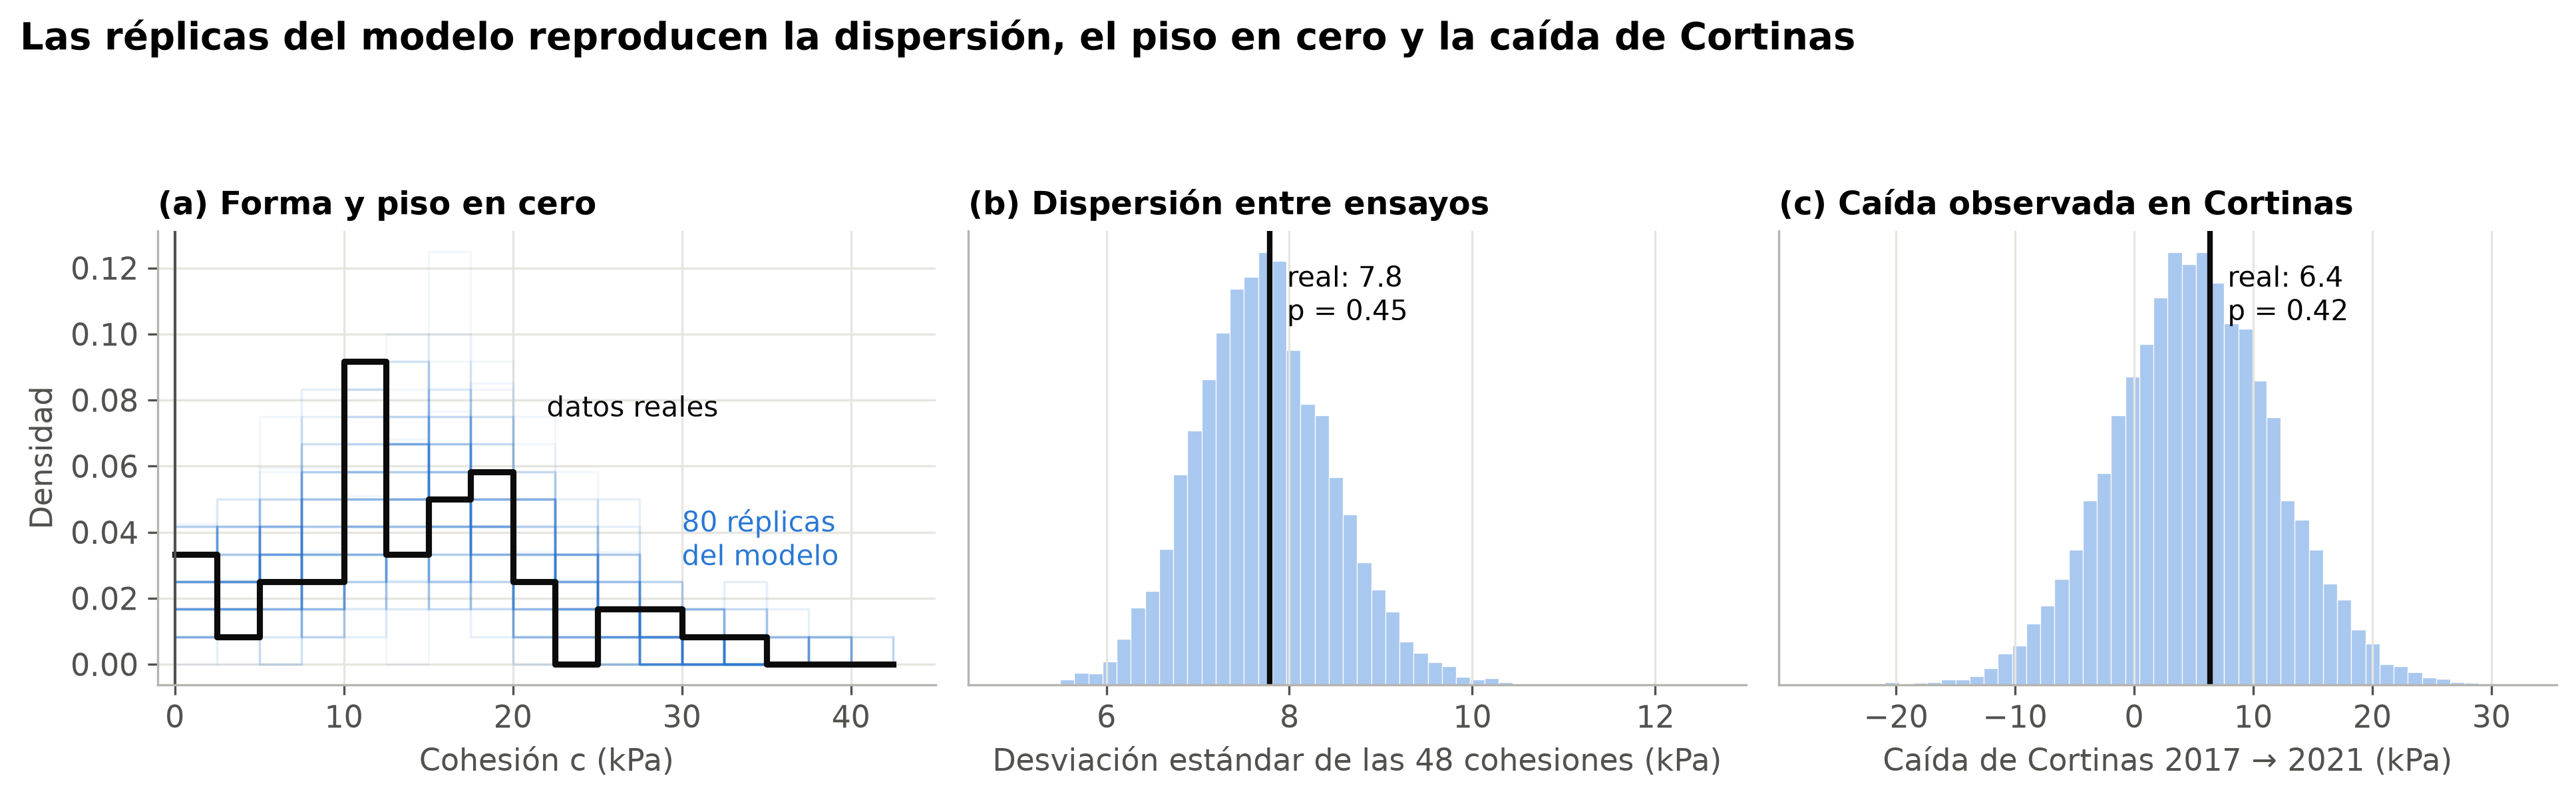

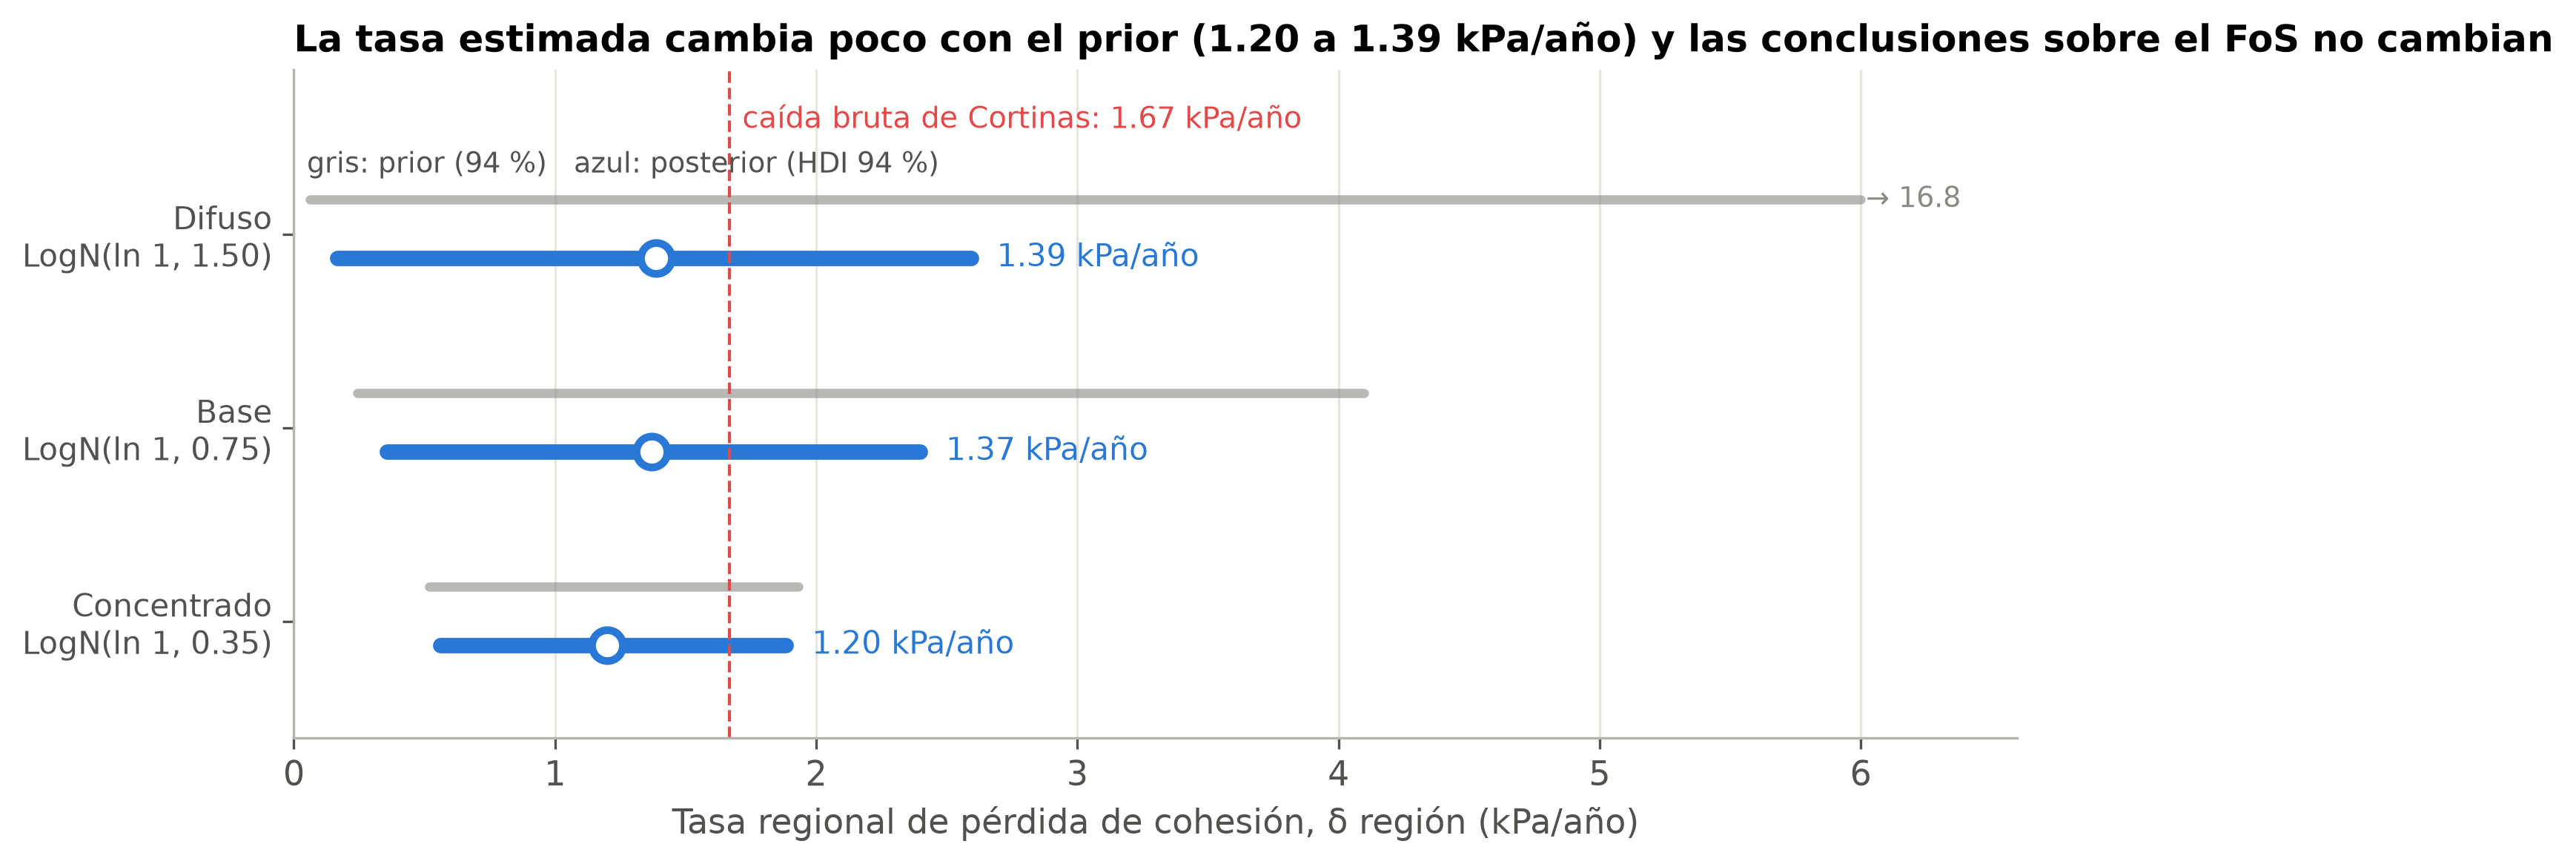

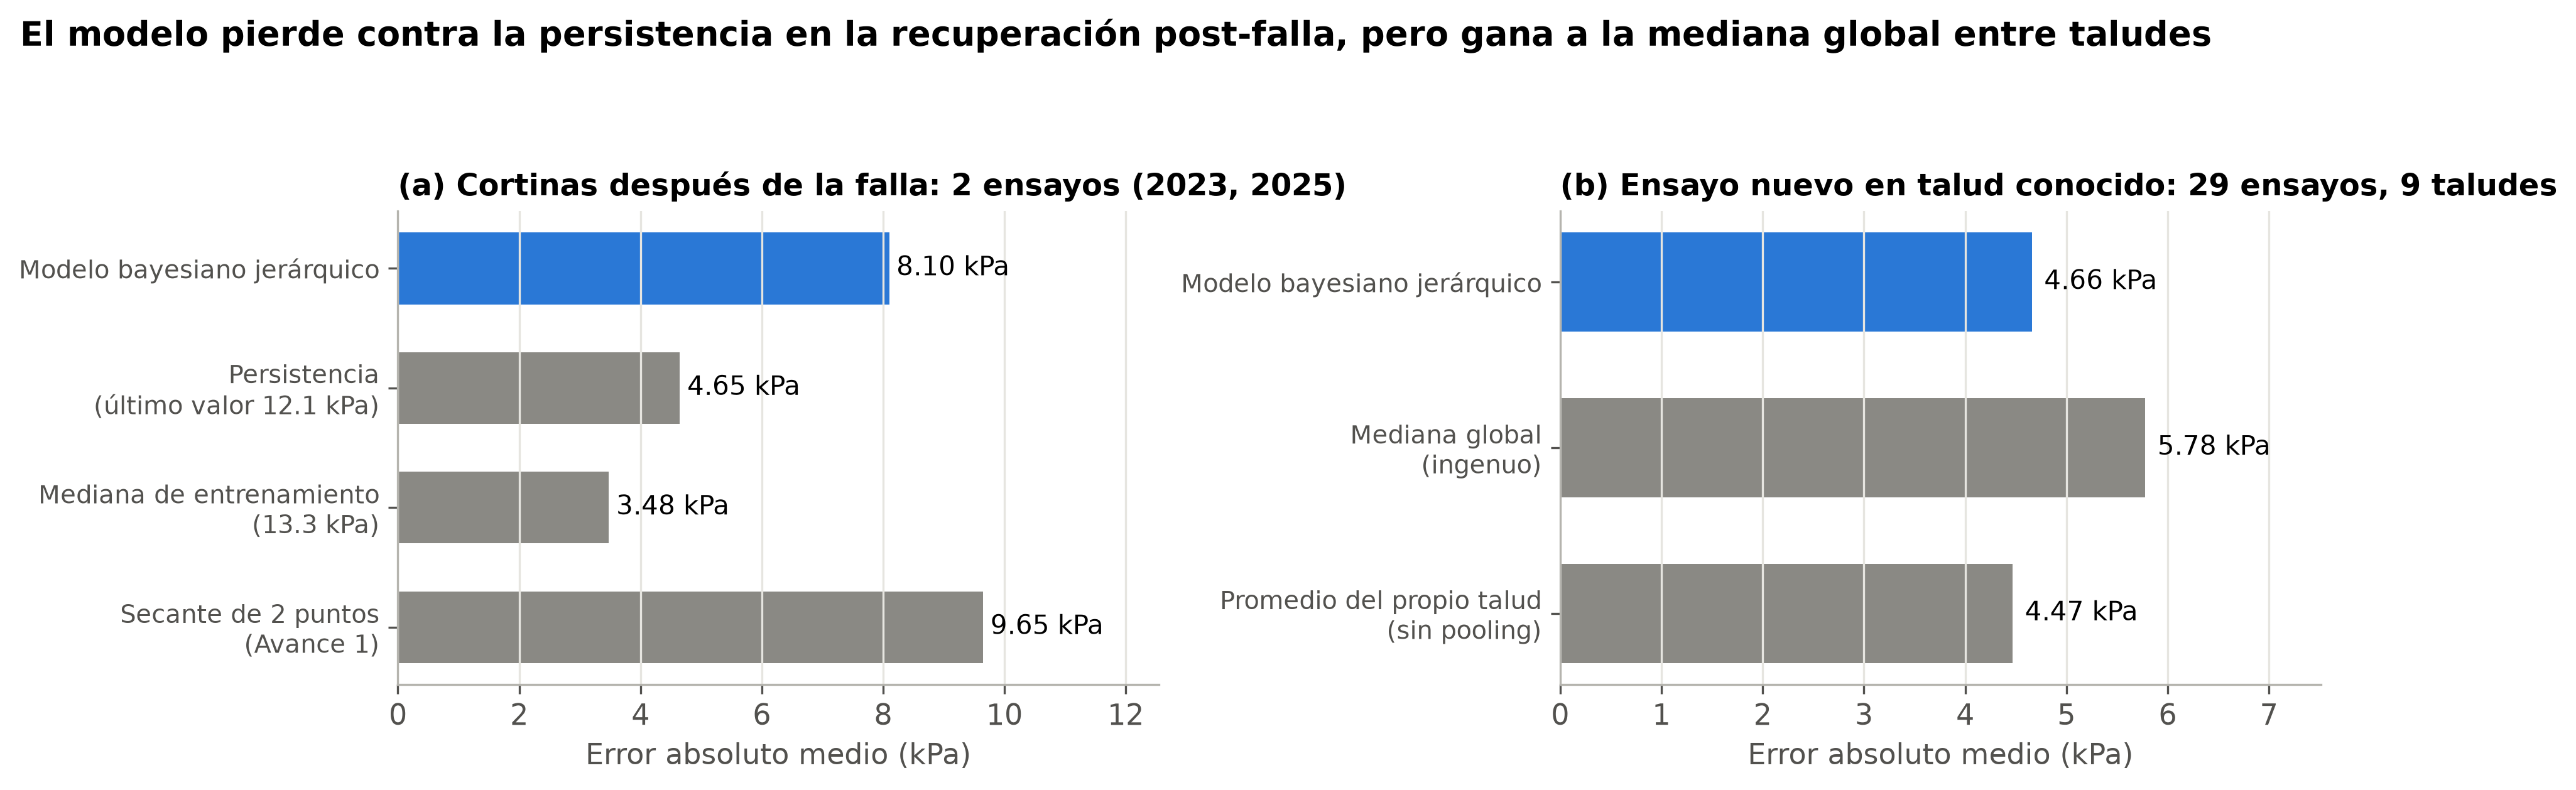

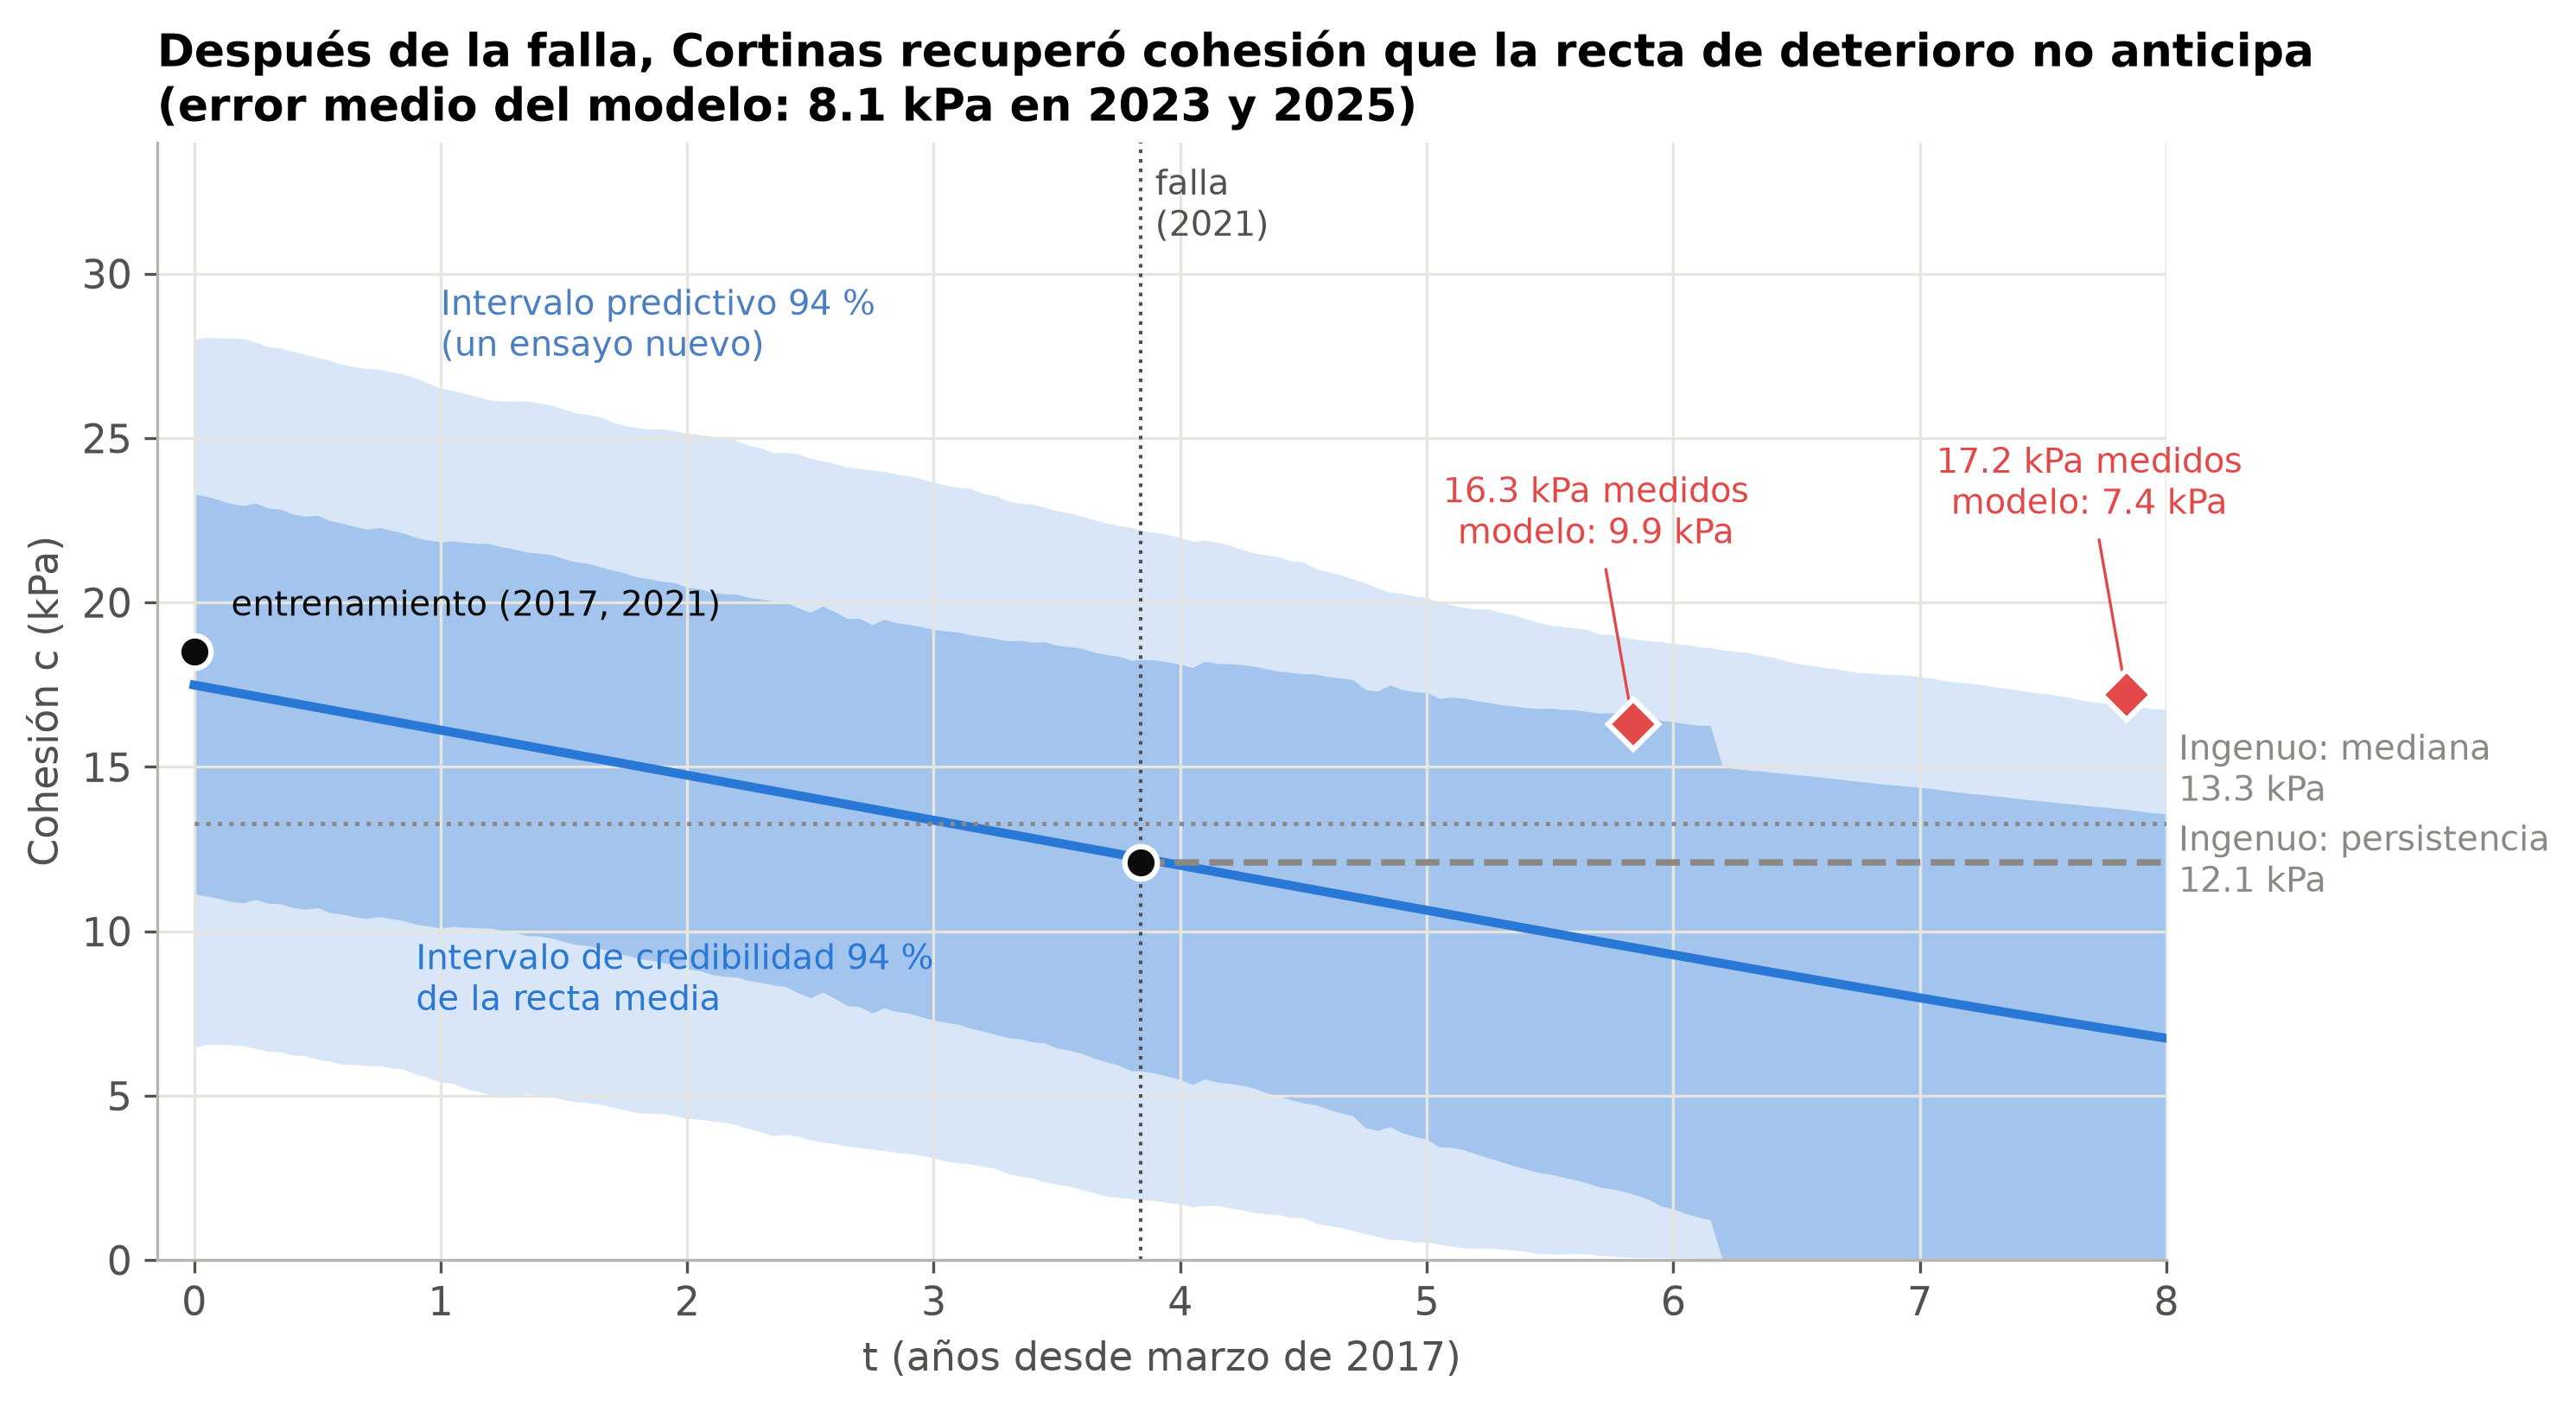

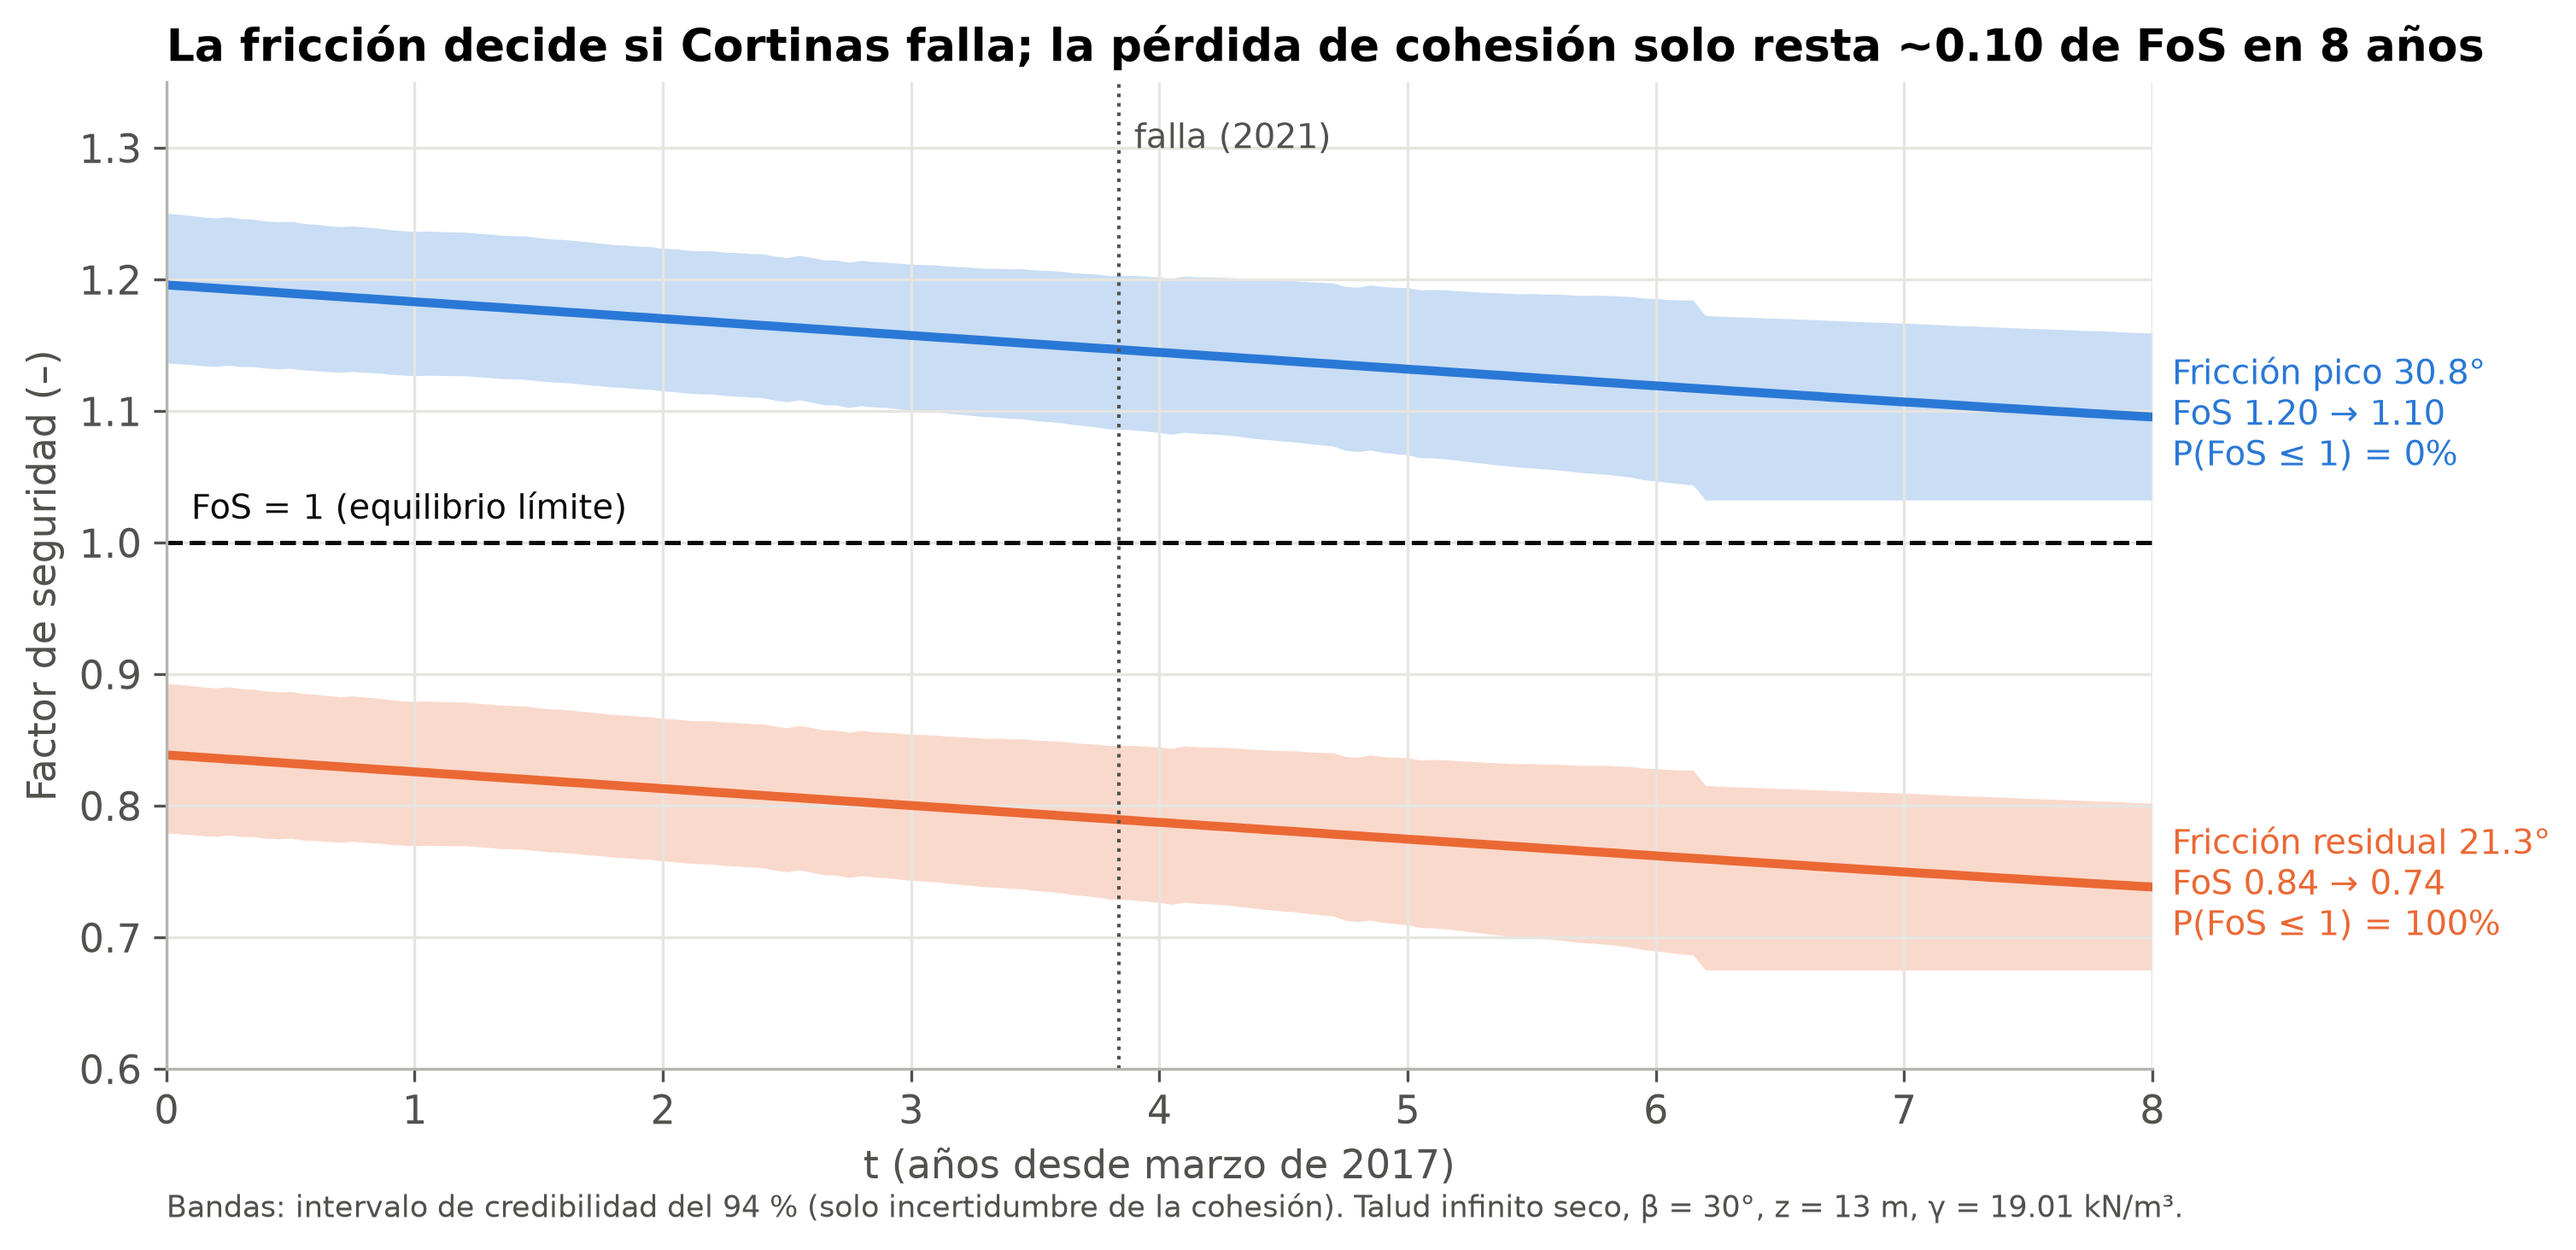

In [15]:
%run generar_figuras_final.py
from IPython.display import Image, display
for nombre in ['fig2_pooling_parcial', 'fig3_ppc', 'fig4_sensibilidad_prior', 'fig5_comparacion_ingenuo',
               'fig7_cortinas_pronostico', 'fig8_fos_escenarios']:
    display(Image(filename=f'figuras/{nombre}.png', width=900))